- The cleaned dataset UNSW provided later only have IoT labels. 
- Therefore, I'll carry on the experiement with the previously provided dataset
- Deakin dataset can't be used because they use Linux cooked encapsulation layer which only expose source MAC and not destination MAC

In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [3]:
pd.set_option("display.max_colwidth", None)

In [4]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [5]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [6]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [7]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)

- Let's relabel the dataset into three categories:
    - Non-iot device
    - IoT device
    - Energy-constrained IoT device (Health-Monitor device)
        - Withings Aura smart sleep sensor,,00:24:e4:20:28:c6,1,sleep sensor,Withings
        - Blipcare Blood Pressure meter,,74:6a:89:00:2e:25,1,blood pressure monitor,Blipcare
        - Netatmo weather station,,70:ee:50:03:b8:ac,1,weather station,Netatmo
        - NEST Protect smoke alarm,,18:b4:30:25:be:e4,1,smoke alarm,Nest
        - Withings Smart scale,,00:24:e4:1b:6f:96,1,smart scale,Withings
- We'll assign them as following:
    - Non-IoT device: `1`
    - Other IoT device: `2`
    - Health-Monitor IoT device: `3` 

In [8]:
health_monitor_devices = set(["74:6a:89:00:2e:25","18:b4:30:25:be:e4","00:24:e4:1b:6f:96"])
# Relabel the device
for mac in device_dict_1:
    if device_dict_1[mac]["is_iot_device"] == 0:
        device_dict_1[mac]["is_iot_device"] = 1
    else:
        if mac in health_monitor_devices:
            device_dict_1[mac]["is_iot_device"] = 3
        else:
            device_dict_1[mac]["is_iot_device"] = 2

for mac in device_dict_1:
    print(f"{mac}: {device_dict_1[mac]['device_name']}")
    print(f"\t'ip_address': {device_dict_1[mac]['ip_address']}")
    print(f"\t'is_iot_device': {device_dict_1[mac]['is_iot_device']}")
    print(f"\t'device_type': {device_dict_1[mac]['device_type']}")
    print(f"\t'vendor': {device_dict_1[mac]['vendor']}")
    print()

d0:52:a8:00:67:5e: Smart Things
	'ip_address': nan
	'is_iot_device': 2
	'device_type': hub
	'vendor': Samsung SmartThings

44:65:0d:56:cc:d3: Amazon Echo
	'ip_address': nan
	'is_iot_device': 2
	'device_type': smart speaker
	'vendor': Amazon

70:ee:50:18:34:43: Netatmo Welcome
	'ip_address': nan
	'is_iot_device': 2
	'device_type': camera
	'vendor': Netatmo

f4:f2:6d:93:51:f1: TP-Link Day Night Cloud camera
	'ip_address': nan
	'is_iot_device': 2
	'device_type': camera
	'vendor': TP-Link

00:16:6c:ab:6b:88: Samsung SmartCam
	'ip_address': nan
	'is_iot_device': 2
	'device_type': camera
	'vendor': Samsung

30:8c:fb:2f:e4:b2: Dropcam
	'ip_address': nan
	'is_iot_device': 2
	'device_type': camera
	'vendor': Dropcam

00:62:6e:51:27:2e: Insteon Camera Wired
	'ip_address': nan
	'is_iot_device': 2
	'device_type': camera
	'vendor': Insteon

e8:ab:fa:19:de:4f: Insteon Camera Wireless
	'ip_address': nan
	'is_iot_device': 2
	'device_type': camera
	'vendor': Insteon

00:24:e4:11:18:a8: Withings Smart B

In [9]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

KPLITS = 5
RANDOM_STATE = 42
WINDOW_SECONDS = 4

In [10]:
# Outgoing volume
def extract_data_from_pcap(
    file_paths: Iterable[str]
) -> pd.DataFrame:
    columns = [
        "frame.time_epoch",
        "frame.len",
        "eth.src",
    ]

    all_data = []

    for file_path in file_paths:
        raw_df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
            }
        )

        raw_df["capture_id"] = Path(file_path).stem
        all_data.append(raw_df)


    res = pd.concat(all_data, ignore_index=True)
    res = res.sort_values(
        ["frame.time_epoch", "eth.src"],
        ignore_index=True,
    )

    return res


In [11]:
all_data = extract_data_from_pcap(csv_files_1)

In [12]:
def label_features(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]]
) -> pd.DataFrame:

    unknown_macs = set(features["eth.src"]) - set(device_mapping)

    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    res = features.copy()
    res["is_iot_device"] = res["eth.src"].map(
        lambda x: device_mapping[x]["is_iot_device"]
    )
    res["device_type"] = res["eth.src"].map(
        lambda x: device_mapping[x]["device_type"]
    )
    res["vendor"] = res["eth.src"].map(
        lambda x: device_mapping[x]["vendor"]
    )

    return res

In [13]:
eda_df = all_data.copy()

In [14]:
result = (
    eda_df.groupby("eth.src", observed=True)["capture_id"]
      .unique()
      .reset_index()
)
result

,eth.src,capture_id
0,00:16:6c:ab:6b:88,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
1,00:24:e4:10:ee:4c,[16-10-07]
2,00:24:e4:11:18:a8,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07]"
3,00:24:e4:1b:6f:96,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
4,00:24:e4:20:28:c6,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
5,00:62:6e:51:27:2e,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
6,08:21:ef:3b:fc:e3,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
7,14:cc:20:51:33:ea,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
8,18:b4:30:25:be:e4,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11]"
9,18:b7:9e:02:20:44,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"


In [15]:
capture_counts = (
    eda_df.groupby("eth.src")["capture_id"]
      .nunique()
)

single_capture_devices = capture_counts[
    capture_counts == 1
].index

single_capture_info = (
    eda_df[eda_df["eth.src"].isin(single_capture_devices)]
    [
        ["eth.src"]
    ]
    .drop_duplicates()
    .sort_values("eth.src")
)
# single_capture_info = label_features(single_capture_info, device_dict_1)
# single_capture_info_with_label = label_features(single_capture_info, device_dict_1)
single_capture_info

,eth.src
14277807,00:24:e4:10:ee:4c
14462901,30:8c:fb:b6:ea:45
4086408,8a:05:81:fa:cc:14
4141401,d2:13:91:23:2a:58
4380280,e8:ab:fa:19:de:4f
11023487,f4:5c:89:93:cc:85


In [16]:
# exclude_devices = ["00:24:e4:1b:6f:96", "18:b4:30:25:be:e4", "74:6a:89:00:2e:25"]
exclude_devices = []

# camera_devices = ["70:ee:50:18:34:43","30:8c:fb:2f:e4:b2","00:16:6c:ab:6b:88","f4:f2:6d:93:51:f1","00:62:6e:51:27:2e"]
camera_devices = []

gateway = "14:cc:20:51:33:ea"
exclude_devices.extend(camera_devices)
exclude_devices.append(gateway)

# exclude_devices = []
exclude_devices.extend(single_capture_info["eth.src"].to_list())
exclude_devices

['14:cc:20:51:33:ea',
 '00:24:e4:10:ee:4c',
 '30:8c:fb:b6:ea:45',
 '8a:05:81:fa:cc:14',
 'd2:13:91:23:2a:58',
 'e8:ab:fa:19:de:4f',
 'f4:5c:89:93:cc:85']

In [17]:
device_to_be_include = set(device_dict_1) - set(exclude_devices)
len(device_to_be_include)

27

In [18]:
process_df = all_data.copy()

In [19]:
list_of_devices_to_be_classified = list(device_to_be_include)
print(f"Total: {len(list_of_devices_to_be_classified)} devices")
for mac in list_of_devices_to_be_classified:
    print(f"mac '{mac}': {device_dict_1[mac]["device_name"]},\tis_iot: {device_dict_1[mac]["is_iot_device"]}, \tdevice_type: {device_dict_1[mac]["device_type"]}")

Total: 27 devices
mac 'd0:52:a8:00:67:5e': Smart Things,	is_iot: 2, 	device_type: hub
mac '00:62:6e:51:27:2e': Insteon Camera Wired,	is_iot: 2, 	device_type: camera
mac '18:b4:30:25:be:e4': NEST Protect smoke alarm,	is_iot: 3, 	device_type: smoke alarm
mac '18:b7:9e:02:20:44': Triby Speaker,	is_iot: 2, 	device_type: smart speaker
mac '00:24:e4:20:28:c6': Withings Aura smart sleep sensor,	is_iot: 2, 	device_type: sleep sensor
mac '50:c7:bf:00:56:39': TP-Link Smart plug,	is_iot: 2, 	device_type: smart plug
mac '74:6a:89:00:2e:25': Blipcare Blood Pressure meter,	is_iot: 3, 	device_type: blood pressure monitor
mac 'ac:bc:32:d4:6f:2f': MacBook,	is_iot: 1, 	device_type: nan
mac 'b4:ce:f6:a7:a3:c2': Android Phone,	is_iot: 1, 	device_type: nan
mac '30:8c:fb:2f:e4:b2': Dropcam,	is_iot: 2, 	device_type: camera
mac '70:ee:50:03:b8:ac': Netatmo weather station,	is_iot: 2, 	device_type: weather station
mac '08:21:ef:3b:fc:e3': Samsung Galaxy Tab,	is_iot: 1, 	device_type: nan
mac '74:2f:68:81:69:42'

In [20]:
# Only outgoing feature
def build_feature(raw_df: pd.DataFrame, device_to_be_include: set, window: int = WINDOW_SECONDS) -> pd.DataFrame:
    if window <= 0:
        raise ValueError("window must be greater than 0")

    all_features = []
    df = raw_df.copy()
    for capture_id, capture_df in df.groupby(
        "capture_id",
        sort=False,
        observed=True,
    ):
        capture_df = capture_df.copy()

        # All devices appearing as eth.src in this capture
        devices = capture_df["eth.src"].dropna().unique()

        devices = np.array([
            device
            for device in devices
            if device in device_to_be_include
        ])

        capture_start = capture_df["frame.time_epoch"].min()
        capture_end = capture_df["frame.time_epoch"].max()

        # Assign packets to globally aligned windows for this capture
        capture_df["window"] = (
            (capture_df["frame.time_epoch"] - capture_start) // window
        ).astype("int32")


        # Calculate features where packets actually exist
        features = (
            capture_df[
                capture_df["eth.src"].isin(devices)
            ]
            .groupby(
                ["window", "eth.src"],
                sort=False,
                observed=True,
            )
            .agg(
                packet_count=("frame.len", "size"),
                total_bytes=("frame.len", "sum"),
            )
        )

        # Missing device/window combinations become zero
        features = (
            features
            .reset_index()
        )

        features["capture_id"] = capture_id

        all_features.append(features)

    if not all_features:
        return pd.DataFrame(
            columns=[
                "capture_id",
                "window",
                "eth.src",
                "packet_count",
                "total_bytes",
            ]
        )

    result = pd.concat(
        all_features,
        ignore_index=True,
    )

    result["packet_count"] = result["packet_count"].astype("int64")
    result["total_bytes"] = result["total_bytes"].astype("int64")

    return result[
        [
            "capture_id",
            "window",
            "eth.src",
            "packet_count",
            "total_bytes",
        ]
    ]


In [21]:
features = build_feature(raw_df=process_df, device_to_be_include=device_to_be_include, window=7200)

In [22]:
labeled_features = label_features(features=features, device_mapping=device_dict_1)

In [23]:
labeled_features[(labeled_features["packet_count"] == 0) & (labeled_features["total_bytes"] == 0) & (labeled_features["is_iot_device"] == 1)].head(10)

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor


In [24]:
labeled_features[(labeled_features["packet_count"] == 0) & (labeled_features["total_bytes"] == 0) & (labeled_features["is_iot_device"] == 0)]

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor


In [25]:
data_df = labeled_features.copy()

In [26]:
def create_under_sampler(random_seed: int = 42) -> RandomUnderSampler:
    """
    Create a RandomUnderSampler for undersampling the majority class.

    Args:
        random_seed (int): Random seed for reproducibility.

    Returns:
        RandomUnderSampler: An instance of the RandomUnderSampler.
    """
    return RandomUnderSampler(random_state=random_seed)

def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight="balanced",
        random_state=random_seed,
    )

In [27]:
def device_capture_repeated_split(
    df: pd.DataFrame,
    list_of_devices_to_be_classified,
    n_splits: int = 5,
    random_state: int = 42,
):
    target_devices = set(list_of_devices_to_be_classified)

    # ---------------------------------------------------------
    # Rows belonging to devices we want to classify
    # ---------------------------------------------------------
    target_mask = df["eth.src"].isin(target_devices).to_numpy()
    target_positions = np.flatnonzero(target_mask)

    work_df = df.iloc[target_positions][
        ["eth.src", "capture_id"]
    ].copy()

    # ---------------------------------------------------------
    # Validate devices
    # ---------------------------------------------------------
    existing_devices = set(work_df["eth.src"].unique())

    missing_devices = target_devices - existing_devices

    if missing_devices:
        raise ValueError(
            f"Devices not found in dataframe: {missing_devices}"
        )

    # Unique (device, capture) pairs
    device_captures = (
        work_df
        .drop_duplicates()
        .reset_index(drop=True)
    )

    capture_counts = (
        device_captures
        .groupby("eth.src", observed=True)
        .size()
    )

    # A device needs at least 2 captures to have
    # capture-separated train AND validation data.
    insufficient = capture_counts[capture_counts < 2]

    if not insufficient.empty:
        raise ValueError(
            "These devices have fewer than 2 capture_ids, "
            "so capture-level train/validation separation is impossible:\n"
            f"{insufficient}"
        )

    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Precompute shuffled capture list for each device
    # ---------------------------------------------------------
    captures_by_device = {}

    for device, group in device_captures.groupby(
        "eth.src",
        observed=True,
        sort=False,
    ):
        captures = group["capture_id"].to_numpy().copy()
        rng.shuffle(captures)

        captures_by_device[device] = captures

    # ---------------------------------------------------------
    # Build repeated splits
    # ---------------------------------------------------------
    folds = []

    row_devices = work_df["eth.src"].to_numpy()
    row_captures = work_df["capture_id"].to_numpy()

    for fold_idx in range(n_splits):

        # Which capture is validation for each device
        val_capture_by_device = {
            device: captures[fold_idx % len(captures)]
            for device, captures in captures_by_device.items()
        }

        # Construct validation mask
        val_mask = np.zeros(
            len(work_df),
            dtype=bool,
        )

        for device, val_capture in val_capture_by_device.items():
            val_mask |= (
                (row_devices == device)
                & (row_captures == val_capture)
            )

        folds.append(
            {
                "fold": fold_idx,
                "train_iloc": target_positions[~val_mask],
                "val_iloc": target_positions[val_mask],
                "val_capture_by_device": val_capture_by_device,
            }
        )

    return folds

In [28]:
training_and_validation_folds = device_capture_repeated_split(
    df=data_df,
    list_of_devices_to_be_classified=list_of_devices_to_be_classified,
    n_splits=KPLITS,
    random_state=RANDOM_STATE
)

In [29]:
for fold in training_and_validation_folds:
    train_df = data_df.iloc[fold["train_iloc"]]
    val_df = data_df.iloc[fold["val_iloc"]]
    print(f"Fold {fold["fold"]}:")
    for device in list_of_devices_to_be_classified:
        train_captures = set(
            train_df.loc[
                train_df["eth.src"] == device,
                "capture_id",
            ]
        )

        val_captures = set(
            val_df.loc[
                val_df["eth.src"] == device,
                "capture_id",
            ]
        )
        print(f"\tMac {device}: trained on {train_captures}, validated on {val_captures}")

        assert train_captures.isdisjoint(val_captures)

print("No capture leakage.")

Fold 0:
	Mac d0:52:a8:00:67:5e: trained on {'16-09-25', '16-09-23', '16-10-07', '16-09-24', '16-10-01', '16-10-08', '16-09-30', '16-10-06', '16-09-26', '16-10-09', '16-10-12', '16-09-29', '16-09-28', '16-10-05', '16-10-10', '16-09-27', '16-10-04', '16-10-02', '16-10-03'}, validated on {'16-10-11'}
	Mac 00:62:6e:51:27:2e: trained on {'16-10-12', '16-09-29', '16-10-07', '16-10-01', '16-09-28', '16-10-05', '16-10-08', '16-09-30', '16-10-04', '16-10-11', '16-10-06', '16-10-02', '16-10-03', '16-10-09'}, validated on {'16-10-10'}
	Mac 18:b4:30:25:be:e4: trained on {'16-09-25', '16-09-23', '16-10-03', '16-09-29', '16-10-07', '16-09-24', '16-10-01', '16-09-28', '16-10-05', '16-10-08', '16-09-30', '16-10-04', '16-10-11', '16-10-06', '16-10-02', '16-09-27', '16-09-26', '16-10-09'}, validated on {'16-10-10'}
	Mac 18:b7:9e:02:20:44: trained on {'16-09-25', '16-09-23', '16-10-07', '16-09-24', '16-10-01', '16-09-30', '16-10-06', '16-09-26', '16-10-09', '16-10-12', '16-09-29', '16-09-28', '16-10-05',

In [30]:
def evaluate_device_predictions(
    val_df: pd.DataFrame,
    list_of_devices_to_be_classified: list,
    device_dict: dict,
) -> Tuple[dict, pd.DataFrame]:

    VALID_LABELS = {1, 2, 3}

    expected_devices = set(list_of_devices_to_be_classified)
    actual_devices = set(val_df["eth.src"].unique())

    # ---------------------------------------------------------
    # 1. Verify validation contains exactly the expected devices
    # ---------------------------------------------------------
    if actual_devices != expected_devices:
        missing = expected_devices - actual_devices
        unexpected = actual_devices - expected_devices

        raise ValueError(
            f"Device mismatch.\n"
            f"Missing from validation: {missing}\n"
            f"Unexpected in validation: {unexpected}"
        )

    # ---------------------------------------------------------
    # 2. Verify predictions are valid
    # ---------------------------------------------------------
    prediction_values = set(
        val_df["prediction_each_window"].dropna().unique()
    )

    if not prediction_values.issubset(VALID_LABELS):
        raise ValueError(
            f"Predictions must be one of {VALID_LABELS}. "
            f"Found: {prediction_values}"
        )

    # ---------------------------------------------------------
    # 3. Aggregate window predictions for each device
    # ---------------------------------------------------------
    evaluation = (
        val_df
        .groupby("eth.src", observed=True)
        ["prediction_each_window"]
        .agg(
            total_predictions="size",
            prediction_1=lambda x: (x == 1).sum(),
            prediction_2=lambda x: (x == 2).sum(),
            prediction_3=lambda x: (x == 3).sum(),
        )
        .reset_index()
    )

    # ---------------------------------------------------------
    # 4. Majority voting
    #
    # idxmax resolves ties by selecting the first column:
    # prediction_1 -> prediction_2 -> prediction_3
    # ---------------------------------------------------------
    prediction_columns = [
        "prediction_1",
        "prediction_2",
        "prediction_3",
    ]

    evaluation["aggregated_prediction"] = (
        evaluation[prediction_columns]
        .idxmax(axis=1)
        .str.replace("prediction_", "", regex=False)
        .astype(int)
    )

    # ---------------------------------------------------------
    # 5. Add true labels
    # ---------------------------------------------------------
    evaluation = label_features(
        features=evaluation,
        device_mapping=device_dict,
    )

    true_labels = evaluation["is_iot_device"]
    predicted_labels = evaluation["aggregated_prediction"]

    # ---------------------------------------------------------
    # 6. Accuracy
    # ---------------------------------------------------------
    accuracy = accuracy_score(
        true_labels,
        predicted_labels,
    )

    # ---------------------------------------------------------
    # 7. Misclassified devices
    # ---------------------------------------------------------
    misclassified_df = evaluation.loc[
        true_labels != predicted_labels
    ].copy()

    misclassified_devices = (
        misclassified_df["eth.src"].tolist()
    )

    # ---------------------------------------------------------
    # 8. Device count for each class
    # ---------------------------------------------------------
    class_1_device_count = evaluation.loc[
        evaluation["is_iot_device"] == 1,
        "eth.src"
    ].nunique()

    class_2_device_count = evaluation.loc[
        evaluation["is_iot_device"] == 2,
        "eth.src"
    ].nunique()

    class_3_device_count = evaluation.loc[
        evaluation["is_iot_device"] == 3,
        "eth.src"
    ].nunique()

    # ---------------------------------------------------------
    # 9. Confusion matrix
    #
    # Row    = true class
    # Column = predicted class
    # ---------------------------------------------------------
    cm = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[1, 2, 3],
    )

    confusion_matrix_df = pd.DataFrame(
        cm,
        index=[
            "true_1",
            "true_2",
            "true_3",
        ],
        columns=[
            "predicted_1",
            "predicted_2",
            "predicted_3",
        ],
    )

    return (
        {
            "accuracy": accuracy,

            "class_1_device_count": class_1_device_count,
            "class_2_device_count": class_2_device_count,
            "class_3_device_count": class_3_device_count,

            "misclassified_count": len(misclassified_devices),
            "misclassified_devices": misclassified_devices,

            # Confusion matrix flattened
            "true_1_pred_1": cm[0, 0],
            "true_1_pred_2": cm[0, 1],
            "true_1_pred_3": cm[0, 2],

            "true_2_pred_1": cm[1, 0],
            "true_2_pred_2": cm[1, 1],
            "true_2_pred_3": cm[1, 2],

            "true_3_pred_1": cm[2, 0],
            "true_3_pred_2": cm[2, 1],
            "true_3_pred_3": cm[2, 2],
        },
        evaluation,
    )

In [31]:
metric = []
detail_metric = []
for fold in training_and_validation_folds:
    train_df = data_df.iloc[fold["train_iloc"]]
    val_df = data_df.iloc[fold["val_iloc"]]

    X_train, y_train = train_df[FEATURE_COLUMNS], train_df[LABEL_COLUMN]
    X_val, y_val = val_df[FEATURE_COLUMNS], val_df[LABEL_COLUMN]
    sampler = create_under_sampler(random_seed=RANDOM_STATE)

    X_train_resampled, y_train_resampled = sampler.fit_resample(
        X_train,
        y_train
    )

    scaler = StandardScaler()
    
    X_train_scaled = scaler.fit_transform(X_train_resampled)
    X_val_scaled = scaler.transform(X_val)

    model = create_decision_tree(random_seed=RANDOM_STATE)
    
    model.fit(
        X_train_scaled,
        y_train_resampled
    )

    y_pred = model.predict(X_val_scaled)
    val_copy = val_df.copy()
    val_copy["prediction_each_window"] = y_pred

    evaluate_metric, detail = evaluate_device_predictions(
        val_df=val_copy, 
        list_of_devices_to_be_classified=list_of_devices_to_be_classified,
        device_dict=device_dict_1
    )
    evaluate_metric["fold"] = fold["fold"]
    detail["fold"] = fold["fold"]
    metric.append(evaluate_metric)
    detail_metric.append(detail)
    


In [32]:
metric_df = pd.DataFrame(metric)
detail_metric_df = pd.concat(detail_metric, ignore_index=True)

In [33]:
metric_df

,accuracy,class_1_device_count,class_2_device_count,class_3_device_count,misclassified_count,misclassified_devices,true_1_pred_1,true_1_pred_2,true_1_pred_3,true_2_pred_1,true_2_pred_2,true_2_pred_3,true_3_pred_1,true_3_pred_2,true_3_pred_3,fold
0,0.888889,6,18,3,3,"[00:24:e4:20:28:c6, 70:5a:0f:e4:9b:c0, ec:1a:59:83:28:11]",6,0,0,3,15,0,0,0,3,0
1,0.740741,6,18,3,7,"[00:24:e4:20:28:c6, 70:ee:50:03:b8:ac, 74:c6:3b:29:d7:1d, ac:bc:32:d4:6f:2f, b4:ce:f6:a7:a3:c2, d0:a6:37:df:a1:e1, e0:76:d0:33:bb:85]",3,3,0,4,14,0,0,0,3,1
2,0.814815,6,18,3,5,"[00:24:e4:20:28:c6, 30:8c:fb:2f:e4:b2, d0:a6:37:df:a1:e1, e0:76:d0:33:bb:85, ec:1a:59:83:28:11]",5,1,0,4,14,0,0,0,3,2
3,0.888889,6,18,3,3,"[00:24:e4:20:28:c6, 18:b7:9e:02:20:44, 70:ee:50:03:b8:ac]",6,0,0,3,15,0,0,0,3,3
4,0.777778,6,18,3,6,"[00:24:e4:20:28:c6, 50:c7:bf:00:56:39, 70:ee:50:03:b8:ac, d0:a6:37:df:a1:e1, e0:76:d0:33:bb:85, ec:1a:59:83:28:11]",5,1,0,5,13,0,0,0,3,4


In [34]:
detail_metric_df.head(10)

,eth.src,total_predictions,prediction_1,prediction_2,prediction_3,aggregated_prediction,is_iot_device,device_type,vendor,fold
0,00:16:6c:ab:6b:88,12,0,12,0,2,2,camera,Samsung,0
1,00:24:e4:11:18:a8,12,4,8,0,2,2,baby monitor,Withings,0
2,00:24:e4:1b:6f:96,2,0,0,2,3,3,smart scale,Withings,0
3,00:24:e4:20:28:c6,12,11,1,0,1,2,sleep sensor,Withings,0
4,00:62:6e:51:27:2e,12,0,12,0,2,2,camera,Insteon,0
5,08:21:ef:3b:fc:e3,12,8,3,1,1,1,NaN,NaN,0
6,18:b4:30:25:be:e4,1,0,0,1,3,3,smoke alarm,Nest,0
7,18:b7:9e:02:20:44,12,2,10,0,2,2,smart speaker,Invoxia,0
8,30:8c:fb:2f:e4:b2,12,2,10,0,2,2,camera,Dropcam,0
9,40:f3:08:ff:1e:da,1,1,0,0,1,1,NaN,NaN,0


# End-to-end pipeline to train on different window size

In [35]:
window_size = [2, 4, 8, 16, 32, 64, 128, 256]
while window_size[-1] < 10800:
    window_size.append(window_size[-1] + 256)

len(window_size)

50

In [36]:
metrics = []
detail_metrics = []
for window in window_size:
    features_window = build_feature(raw_df=process_df, device_to_be_include=device_to_be_include, window=window)
    data_df = label_features(features=features_window, device_mapping=device_dict_1)
    training_and_validation_folds = device_capture_repeated_split(
        df=data_df,
        list_of_devices_to_be_classified=list_of_devices_to_be_classified,
        n_splits=KPLITS,
        random_state=RANDOM_STATE
    )

    for fold in training_and_validation_folds:
        train_df = data_df.iloc[fold["train_iloc"]]
        val_df = data_df.iloc[fold["val_iloc"]]

        X_train, y_train = train_df[FEATURE_COLUMNS], train_df[LABEL_COLUMN]
        X_val, y_val = val_df[FEATURE_COLUMNS], val_df[LABEL_COLUMN]
        # sampler = create_under_sampler(random_seed=RANDOM_STATE)

        # X_train_resampled, y_train_resampled = sampler.fit_resample(
        #     X_train,
        #     y_train
        # )
        X_train_resampled, y_train_resampled = X_train, y_train
        
        scaler = StandardScaler()
        
        X_train_scaled = scaler.fit_transform(X_train_resampled)
        X_val_scaled = scaler.transform(X_val)

        # Remove all inactive window
        

        model = create_decision_tree(random_seed=RANDOM_STATE)
        
        model.fit(
            X_train_scaled,
            y_train_resampled
        )

        y_pred = model.predict(X_val_scaled)
        val_copy = val_df.copy()
        val_copy["prediction_each_window"] = y_pred

        evaluate_metric, detail = evaluate_device_predictions(
            val_df=val_copy, 
            list_of_devices_to_be_classified=list_of_devices_to_be_classified,
            device_dict=device_dict_1
        )
        evaluate_metric["fold"] = fold["fold"]
        evaluate_metric["window_size"] = window

        detail["fold"] = fold["fold"]
        detail["window_size"] = window
        metrics.append(evaluate_metric)
        detail_metrics.append(detail)

In [37]:
metrics_df = pd.DataFrame(metrics)
detail_metrics_df = pd.concat(detail_metrics)

In [38]:
metrics_df.head(2)

,accuracy,class_1_device_count,class_2_device_count,class_3_device_count,misclassified_count,misclassified_devices,true_1_pred_1,true_1_pred_2,true_1_pred_3,true_2_pred_1,true_2_pred_2,true_2_pred_3,true_3_pred_1,true_3_pred_2,true_3_pred_3,fold,window_size
0,0.888889,6,18,3,3,"[00:24:e4:11:18:a8, 18:b7:9e:02:20:44, 74:6a:89:00:2e:25]",6,0,0,2,16,0,1,0,2,0,2
1,0.888889,6,18,3,3,"[08:21:ef:3b:fc:e3, 74:6a:89:00:2e:25, d0:a6:37:df:a1:e1]",4,2,0,0,18,0,1,0,2,1,2


# Export performance

In [39]:
def export_dataframe_to_csv(df: pd.DataFrame, file_name: str) -> None:
    df.to_csv(f"./performance-record/{file_name}.csv", index=False)
export_dataframe_to_csv(metrics_df, "3labels-drop-router-health-monitor-type-3")

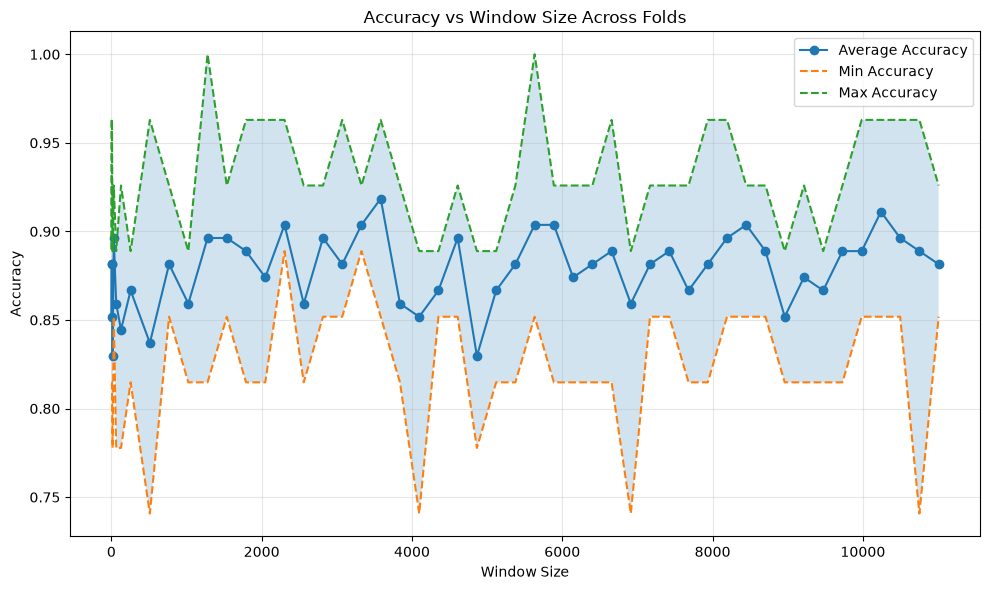

In [40]:
accuracy_summary = (
    metrics_df
    .groupby("window_size")["accuracy"]
    .agg(
        avg_accuracy="mean",
        min_accuracy="min",
        max_accuracy="max"
    )
    .reset_index()
    .sort_values("window_size")
)

plt.figure(figsize=(10, 6))

# Average accuracy
plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["avg_accuracy"],
    marker="o",
    label="Average Accuracy"
)

# Min / Max accuracy
plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["min_accuracy"],
    linestyle="--",
    label="Min Accuracy"
)

plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["max_accuracy"],
    linestyle="--",
    label="Max Accuracy"
)

# Shade the min-max range
plt.fill_between(
    accuracy_summary["window_size"],
    accuracy_summary["min_accuracy"],
    accuracy_summary["max_accuracy"],
    alpha=0.2
)

plt.xlabel("Window Size")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Window Size Across Folds")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
accuracy_summary.sort_values(by=["avg_accuracy", "window_size"], ascending=[False, True]).head(10)

,window_size,avg_accuracy,min_accuracy,max_accuracy
20,3584,0.918519,0.851852,0.962963
46,10240,0.911111,0.851852,0.962963
15,2304,0.903704,0.888889,0.962963
19,3328,0.903704,0.888889,0.925926
28,5632,0.903704,0.851852,1.000000
29,5888,0.903704,0.814815,0.925926
39,8448,0.903704,0.851852,0.925926
4,32,0.896296,0.851852,0.925926
11,1280,0.896296,0.814815,1.000000
12,1536,0.896296,0.851852,0.925926


In [42]:
EXAMINING_WINDOW_SIZE = accuracy_summary.sort_values(
    by=["avg_accuracy", "window_size"],
    ascending=[False, True]
).iloc[0]["window_size"]
EXAMINING_WINDOW_SIZE

np.float64(3584.0)

In [43]:
metrics_df[metrics_df["window_size"] == EXAMINING_WINDOW_SIZE]

,accuracy,class_1_device_count,class_2_device_count,class_3_device_count,misclassified_count,misclassified_devices,true_1_pred_1,true_1_pred_2,true_1_pred_3,true_2_pred_1,true_2_pred_2,true_2_pred_3,true_3_pred_1,true_3_pred_2,true_3_pred_3,fold,window_size
100,0.962963,6,18,3,1,[08:21:ef:3b:fc:e3],5,1,0,0,18,0,0,0,3,0,3584
101,0.925926,6,18,3,2,"[ac:bc:32:d4:6f:2f, b4:ce:f6:a7:a3:c2]",4,2,0,0,18,0,0,0,3,1,3584
102,0.851852,6,18,3,4,"[08:21:ef:3b:fc:e3, 40:f3:08:ff:1e:da, 74:6a:89:00:2e:25, b4:ce:f6:a7:a3:c2]",3,3,0,0,18,0,0,1,2,2,3584
103,0.925926,6,18,3,2,"[ac:bc:32:d4:6f:2f, b4:ce:f6:a7:a3:c2]",4,2,0,0,18,0,0,0,3,3,3584
104,0.925926,6,18,3,2,"[ac:bc:32:d4:6f:2f, b4:ce:f6:a7:a3:c2]",4,2,0,0,18,0,0,0,3,4,3584
